In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
url = "https://data.wprdc.org/datastore/dump/8d76ac6b-5ae8-4428-82a4-043130d17b02"
fire = pd.read_csv(url)

Cumulative Fire Danger Ratings by Neighborhood:
neighborhood
Carrick                      990
Central Business District    759
Mount Washington             752
South Side Flats             740
Squirrel Hill South          725
                            ... 
East Carnegie                 34
Oakwood                       33
Arlington Heights             27
Mount Oliver Borough          24
Regent Square                 24
Name: danger_rating, Length: 91, dtype: int64


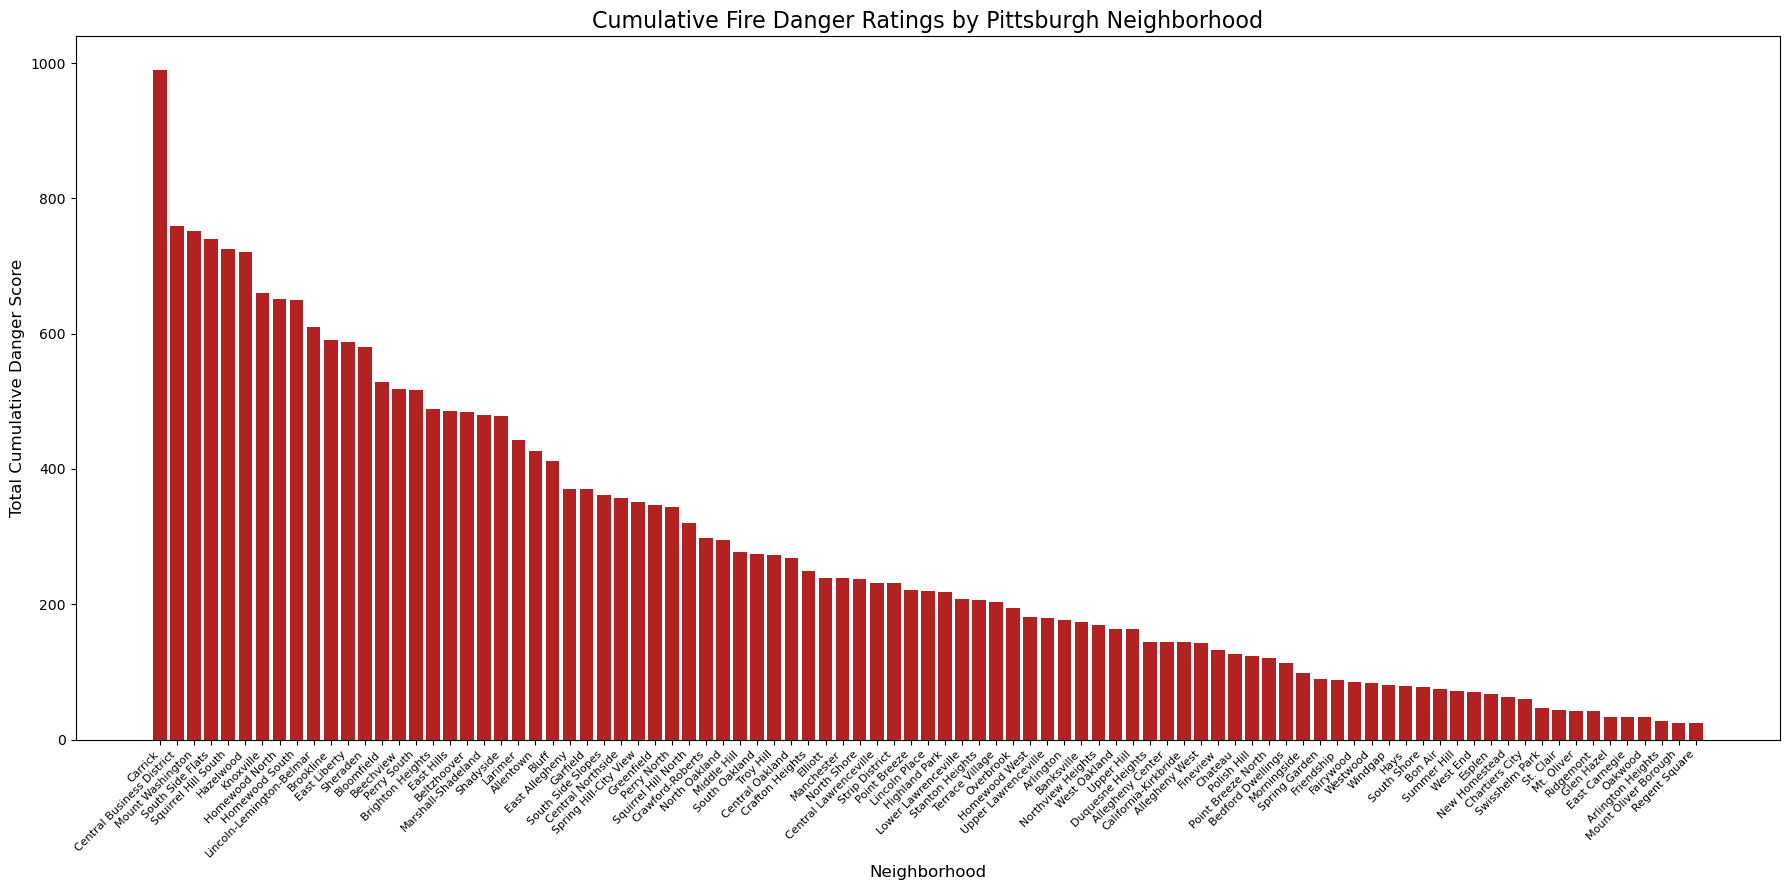

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
url = "https://data.wprdc.org/datastore/dump/8d76ac6b-5ae8-4428-82a4-043130d17b02"
fire = pd.read_csv(url)

# Select and clean necessary columns
fire_subset = fire[["type_description", "neighborhood"]].copy()
fire_subset = fire_subset.dropna(subset=["neighborhood"])
fire_subset = fire_subset[
    fire_subset["neighborhood"].str.strip() != ""
]

# Assign danger ratings to incident types
danger_ratings = {
    "Brush or brush-and-grass mixture fire": 3,
    "Building fire": 5,
    "Camper or recreational vehicle (RV) fire": 4,
    "Chimney or flue fire, confined to chimney or flue": 2,
    "Commercial Compactor fire, confined to rubbish": 2,
    "Construction or demolition landfill fire": 3,
    "Cooking fire, confined to container": 1,
    "Cultivated grain or crop fire": 3,
    "Cultivated orchard or vineyard fire": 3,
    "Cultivated trees or nursery stock fire": 3,
    "Cultivated vegetation, crop fire, Other": 3,
    "Dumpster or other outside trash receptacle fire": 2,
    "Fire in mobile home used as fixed residence": 5,
    "Fire in mobile prop used as a fixed struc, Other": 4,
    "Fire in motor home, camper, recreational vehicle": 4,
    "Fire in portable building, fixed location": 4,
    "Fire, Other": 3,
    "Fires in structure other than in a building": 4,
    "Forest, woods or wildland fire": 5,
    "Fuel burner/boiler malfunction, fire confined": 2,
    "Garbage dump or sanitary landfill fire": 3,
    "Grass fire": 3,
    "Incinerator overload or malfunction, fire confined": 2,
    "Mobile property (vehicle) fire, Other": 4,
    "Natural vegetation fire, Other": 3,
    "Off-road vehicle or heavy equipment fire": 3,
    "Outside equipment fire": 2,
    "Outside gas or vapor combustion explosion": 5,
    "Outside mailbox fire": 1,
    "Outside rubbish fire, Other": 2,
    "Outside rubbish, trash or waste fire": 2,
    "Outside stationary compactor/compacted trash fire": 2,
    "Outside storage fire": 3,
    "Passenger vehicle fire": 4,
    "Rail vehicle fire": 4,
    "Road freight or transport vehicle fire": 5,
    "Self-propelled motor home or recreational vehicle": 4,
    "Special outside fire, Other": 3,
    "Structure fire, Other (conversion only)": 4,
    "Trash or rubbish fire, contained": 1,
    "Water vehicle fire": 4
}

# Apply danger ratings
fire_subset["danger_rating"] = fire_subset[
    "type_description"
].map(danger_ratings)

# Calculate cumulative danger ratings by neighborhood
danger_by_neighborhood = (
    fire_subset.groupby("neighborhood")["danger_rating"]
    .sum()
    .sort_values(ascending=False)
)

# Display results
print("Cumulative Fire Danger Ratings by Neighborhood:")
print(danger_by_neighborhood)

# Create bar graph
plt.figure(figsize=(18, 9))
plt.bar(
    danger_by_neighborhood.index,
    danger_by_neighborhood.values,
    color="firebrick"
)

plt.title("Cumulative Fire Danger Ratings by Pittsburgh Neighborhood",
          fontsize=16)
plt.xlabel("Neighborhood", fontsize=12)
plt.ylabel("Total Cumulative Danger Score", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.show()
